# Lab 7: AlexNet from Scratch

**Name:** Ramnath Thakur &nbsp;&nbsp;|&nbsp;&nbsp; **Roll No.:** 123CS0965 &nbsp;&nbsp;|&nbsp;&nbsp; **Date:** 7 October 2026

AlexNet (Krizhevsky et al., 2012) implemented layer by layer in TensorFlow/Keras and trained from random initialisation
to classify synthetic images of circles, rectangles and triangles.

## 1. Imports and random seeds

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import random
import time
import numpy as np
import cv2
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

%config InlineBackend.figure_format = "retina"

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("NumPy     :", np.__version__)
print("OpenCV    :", cv2.__version__)

I0000 00:00:1791782386.365385    9464 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1791782388.517550    9464 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow: 2.21.0
NumPy     : 2.5.3
OpenCV    : 5.0.0


## 2. Dataset

In [2]:
def generate_synthetic_dataset(num_samples=3000, img_size=227):
    images, labels = [], []

    for _ in range(num_samples):
        label  = np.random.randint(0, 3)
        img    = np.ones((img_size, img_size, 3), dtype=np.uint8) * 200
        color  = tuple(np.random.randint(30, 200, 3).tolist())
        cx, cy = np.random.randint(60, 167), np.random.randint(60, 167)

        if label == 0:          # circle
            r = np.random.randint(30, 60)
            cv2.circle(img, (cx, cy), r, color, -1)

        elif label == 1:        # rectangle
            w = np.random.randint(40, 100)
            h = np.random.randint(40, 100)
            cv2.rectangle(img,
                          (cx - w//2, cy - h//2),
                          (cx + w//2, cy + h//2),
                          color, -1)

        else:                   # triangle
            pts = np.array([
                [cx,      cy - 50],
                [cx - 50, cy + 50],
                [cx + 50, cy + 50]
            ], np.int32)
            cv2.fillPoly(img, [pts], color)

        images.append(img / 255.0)
        labels.append(label)

    images = np.array(images, dtype=np.float32)
    labels = np.array(labels, dtype=np.int32)

    idx = np.random.permutation(len(images))
    images, labels = images[idx], labels[idx]

    split = int(0.8 * num_samples)
    return (images[:split], labels[:split]), (images[split:], labels[split:])

In [3]:
CLASS_NAMES = ["Circle", "Rectangle", "Triangle"]

(x_train, y_train), (x_test, y_test) = generate_synthetic_dataset()

print("x_train:", x_train.shape, x_train.dtype, " y_train:", y_train.shape)
print("x_test :", x_test.shape, x_test.dtype, " y_test :", y_test.shape)
print("Pixel range:", x_train.min(), "to", x_train.max())
print("Train class counts:", dict(zip(CLASS_NAMES, np.bincount(y_train).tolist())))
print("Test  class counts:", dict(zip(CLASS_NAMES, np.bincount(y_test).tolist())))

x_train: (2400, 227, 227, 3) float32  y_train: (2400,)
x_test : (600, 227, 227, 3) float32  y_test : (600,)


Pixel range: 0.11764706 to 0.78431374
Train class counts: {'Circle': 807, 'Rectangle': 789, 'Triangle': 804}
Test  class counts: {'Circle': 207, 'Rectangle': 195, 'Triangle': 198}


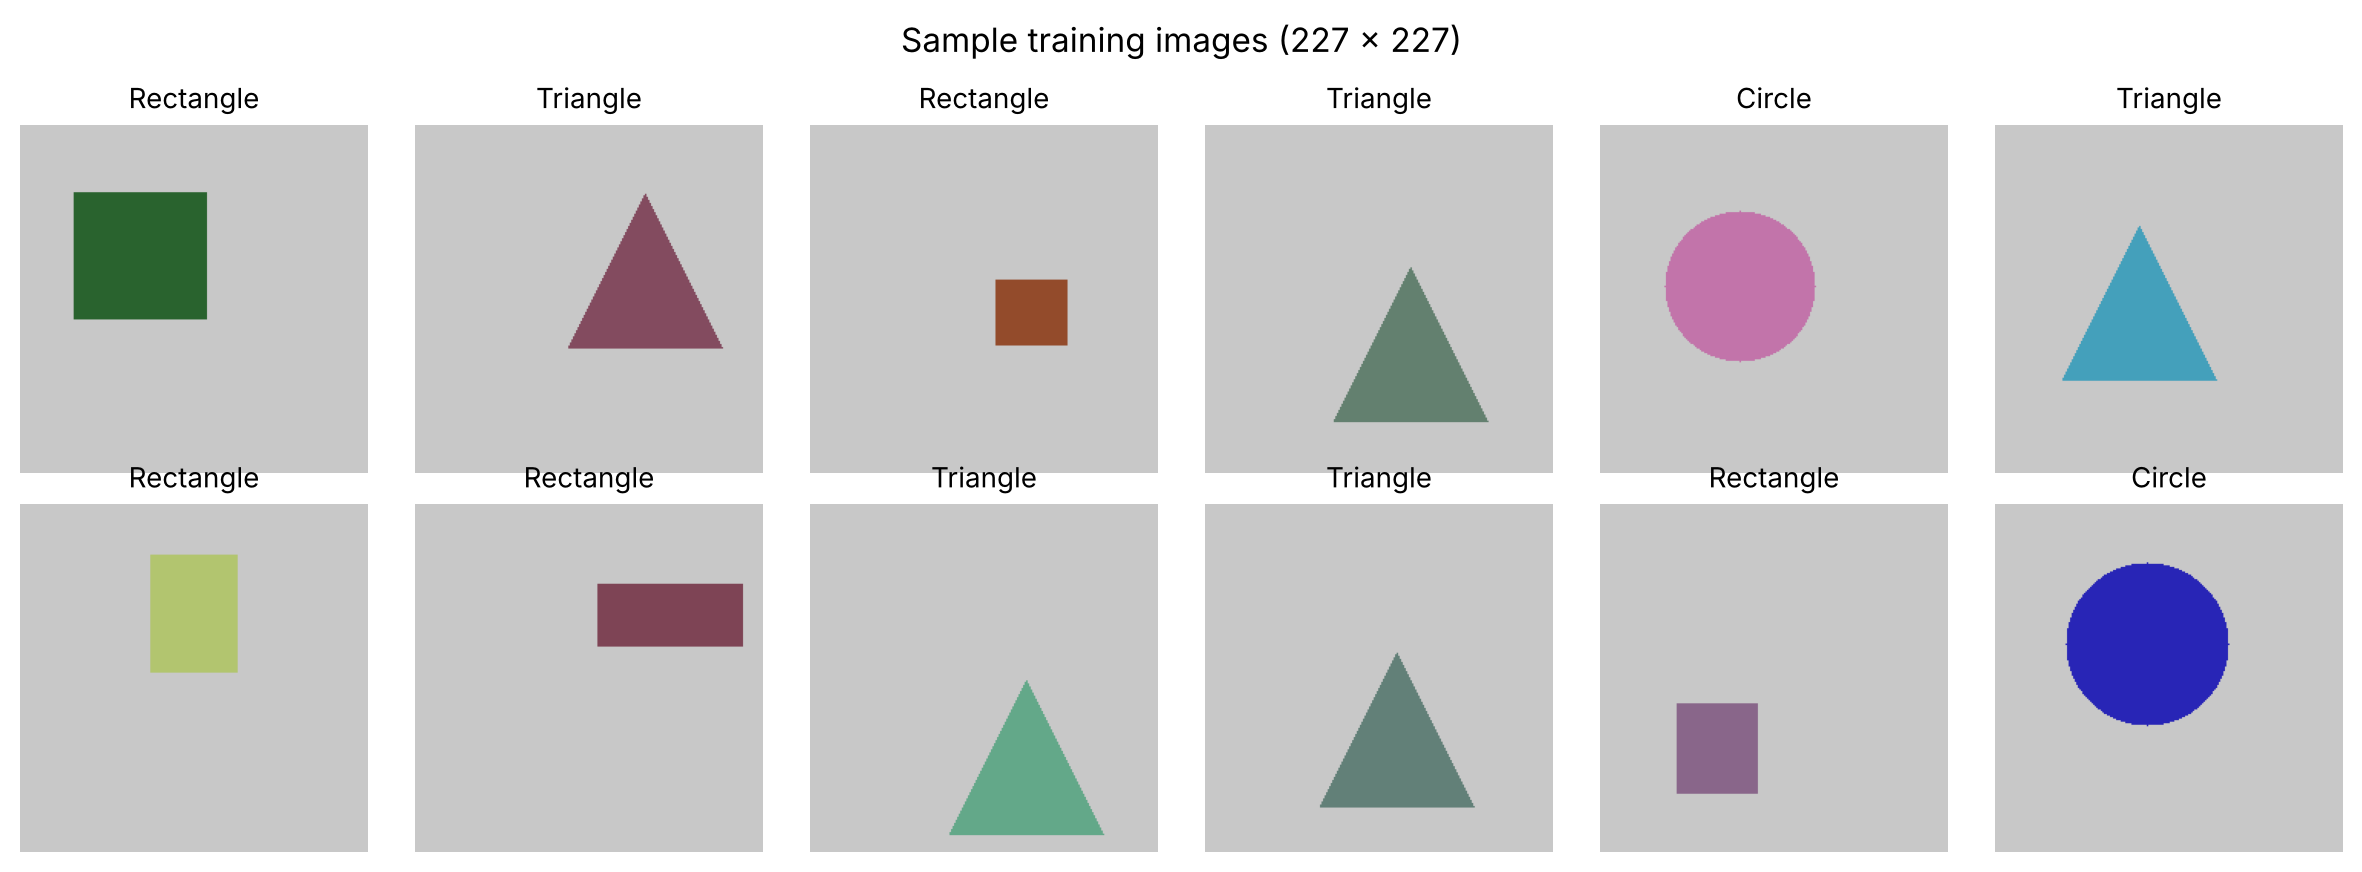

In [4]:
fig, axes = plt.subplots(2, 6, figsize=(12, 4.4))
for ax, i in zip(axes.ravel(), range(12)):
    ax.imshow(x_train[i])
    ax.set_title(CLASS_NAMES[y_train[i]], fontsize=10)
    ax.axis("off")
plt.suptitle("Sample training images (227 x 227)")
plt.tight_layout()
plt.show()

## 3. Local Response Normalization

Keras has no built-in LRN layer, so it is wrapped in a custom layer around `tf.nn.local_response_normalization`.
The hyper-parameters are the ones from Section 3.3 of the paper: k = 2, n = 5 (so `depth_radius = 2`),
alpha = 10<sup>-4</sup>, beta = 0.75. Each activation is divided by the activity of its n neighbouring channels at the same position:

`b[i] = a[i] / (k + alpha * sum(a[j]^2)) ^ beta`, where j runs over the 5 channels centred on i.

In [5]:
class LocalResponseNormalization(layers.Layer):
    def __init__(self, depth_radius=2, bias=2.0, alpha=1e-4, beta=0.75, **kwargs):
        super().__init__(**kwargs)
        self.depth_radius = depth_radius
        self.bias = bias
        self.alpha = alpha
        self.beta = beta

    def call(self, inputs):
        return tf.nn.local_response_normalization(
            inputs,
            depth_radius=self.depth_radius,
            bias=self.bias,
            alpha=self.alpha,
            beta=self.beta,
        )

    def get_config(self):
        config = super().get_config()
        config.update({"depth_radius": self.depth_radius, "bias": self.bias,
                       "alpha": self.alpha, "beta": self.beta})
        return config

Quick check that the layer really changes its input. With k = 2 and beta = 0.75, a channel with small
neighbours is divided by about 2<sup>0.75</sup> ≈ 1.68, and the division grows when neighbouring channels are strongly active.

In [6]:
lrn = LocalResponseNormalization()

# one pixel, 8 channels: two "quiet" channels and one burst of strongly active channels
a = tf.constant([[[[1.0, 1.0, 1.0, 50.0, 60.0, 70.0, 1.0, 1.0]]]])
b = lrn(a)

print("input :", np.round(a.numpy().ravel(), 3))
print("output:", np.round(b.numpy().ravel(), 3))
print("ratio :", np.round((a / b).numpy().ravel(), 3))

input : [ 1.  1.  1. 50. 60. 70.  1.  1.]
output: [ 0.595  0.544  0.487 21.401 25.681 29.961  0.456  0.504]
ratio : [1.682 1.837 2.054 2.336 2.336 2.336 2.194 1.982]


## 4. AlexNet architecture

Every layer is written out explicitly. Spatial sizes for a 227 x 227 x 3 input:

| Layer | Output | Note |
|---|---|---|
| Conv1 11x11/4, 96 | 55 x 55 x 96 | (227 - 11) / 4 + 1 = 55 |
| Pool1 3x3/2 | 27 x 27 x 96 | overlapping pooling |
| Conv2 5x5, 256, same | 27 x 27 x 256 | |
| Pool2 3x3/2 | 13 x 13 x 256 | |
| Conv3, Conv4 3x3, 384, same | 13 x 13 x 384 | |
| Conv5 3x3, 256, same | 13 x 13 x 256 | |
| Pool3 3x3/2 | 6 x 6 x 256 | flattened to 9216 |
| FC1, FC2 | 4096 | dropout 0.5 |
| FC3 | 3 | softmax |

In [7]:
model = models.Sequential(name="AlexNet")

model.add(layers.Input(shape=(227, 227, 3), name="input"))

# Conv block 1
model.add(layers.Conv2D(96, kernel_size=(11, 11), strides=(4, 4), padding="valid",
                        activation="relu", name="conv1"))
model.add(LocalResponseNormalization(name="lrn1"))
model.add(layers.MaxPooling2D(pool_size=(3, 3), strides=(2, 2), name="pool1"))

# Conv block 2
model.add(layers.Conv2D(256, kernel_size=(5, 5), strides=(1, 1), padding="same",
                        activation="relu", name="conv2"))
model.add(LocalResponseNormalization(name="lrn2"))
model.add(layers.MaxPooling2D(pool_size=(3, 3), strides=(2, 2), name="pool2"))

# Conv blocks 3, 4, 5
model.add(layers.Conv2D(384, kernel_size=(3, 3), strides=(1, 1), padding="same",
                        activation="relu", name="conv3"))
model.add(layers.Conv2D(384, kernel_size=(3, 3), strides=(1, 1), padding="same",
                        activation="relu", name="conv4"))
model.add(layers.Conv2D(256, kernel_size=(3, 3), strides=(1, 1), padding="same",
                        activation="relu", name="conv5"))
model.add(layers.MaxPooling2D(pool_size=(3, 3), strides=(2, 2), name="pool3"))

# Classifier
model.add(layers.Flatten(name="flatten"))
model.add(layers.Dense(4096, activation="relu", name="fc1"))
model.add(layers.Dropout(0.5, name="dropout1"))
model.add(layers.Dense(4096, activation="relu", name="fc2"))
model.add(layers.Dropout(0.5, name="dropout2"))
model.add(layers.Dense(3, activation="softmax", name="fc3"))

model.summary()

Model: "AlexNet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 55, 55, 96)     │        34,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lrn1                            │ (None, 55, 55, 96)     │             0 │
│ (LocalResponseNormalization)    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 27, 27, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 27, 27, 256)    │       614,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lrn2                            │ (None, 27, 27, 256)    │             0 │
│ (LocalResponseNormalization)    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 13, 13, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 13, 13, 384)    │       885,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv4 (Conv2D)                  │ (None, 13, 13, 384)    │     1,327,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv5 (Conv2D)                  │ (None, 13, 13, 256)    │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 4096)           │    37,752,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout1 (Dropout)              │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc2 (Dense)                     │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout2 (Dropout)              │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc3 (Dense)                     │ (None, 3)              │        12,291 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 58,293,635 (222.37 MB)

 Trainable params: 58,293,635 (222.37 MB)

 Non-trainable params: 0 (0.00 B)

## 5. Training setup

**Optimizer: Adam, learning rate 10<sup>-4</sup>.**
The paper used SGD with momentum 0.9 and learning rate 0.01, but it also had 1.2 million images, 90 epochs and a
hand-tuned learning-rate schedule. This network has no batch normalisation and about 58 million parameters, most
of them in FC1. Without normalisation layers, SGD on this network is very sensitive to the learning rate: too high and it
diverges, too low and it stays at chance (loss ≈ ln 3 = 1.0986) for a long time. Adam scales each parameter's step by its
own gradient history, so the large FC layers and the small conv filters both get sensible updates without tuning.
A small learning rate is used because a 58 M parameter model on 2400 images can overfit or diverge with a large one.

Loss: sparse categorical cross-entropy (integer labels). Batch size 32, 25 epochs, test set used for validation.

In [8]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

In [9]:
EPOCHS = 25
BATCH_SIZE = 32

start = time.time()
history = model.fit(
    x_train, y_train,
    validation_data=(x_test, y_test),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=2,
)
print(f"\nTraining time: {(time.time() - start) / 60:.1f} min")

Epoch 1/25


75/75 - 111s - 1s/step - accuracy: 0.3137 - loss: 1.1004 - val_accuracy: 0.4067 - val_loss: 1.0985


Epoch 2/25


75/75 - 102s - 1s/step - accuracy: 0.3442 - loss: 1.0910 - val_accuracy: 0.5917 - val_loss: 0.9758


Epoch 3/25


...

Epoch 24/25


75/75 - 101s - 1s/step - accuracy: 1.0000 - loss: 3.6658e-05 - val_accuracy: 1.0000 - val_loss: 5.9386e-04


Epoch 25/25


75/75 - 93s - 1s/step - accuracy: 1.0000 - loss: 1.9400e-05 - val_accuracy: 1.0000 - val_loss: 2.1080e-04



Training time: 40.9 min


## 6. Evaluation on the test set

In [10]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test loss    : {test_loss:.4f}")
print(f"Test accuracy: {test_acc * 100:.2f} %")

Test loss    : 0.0002
Test accuracy: 100.00 %


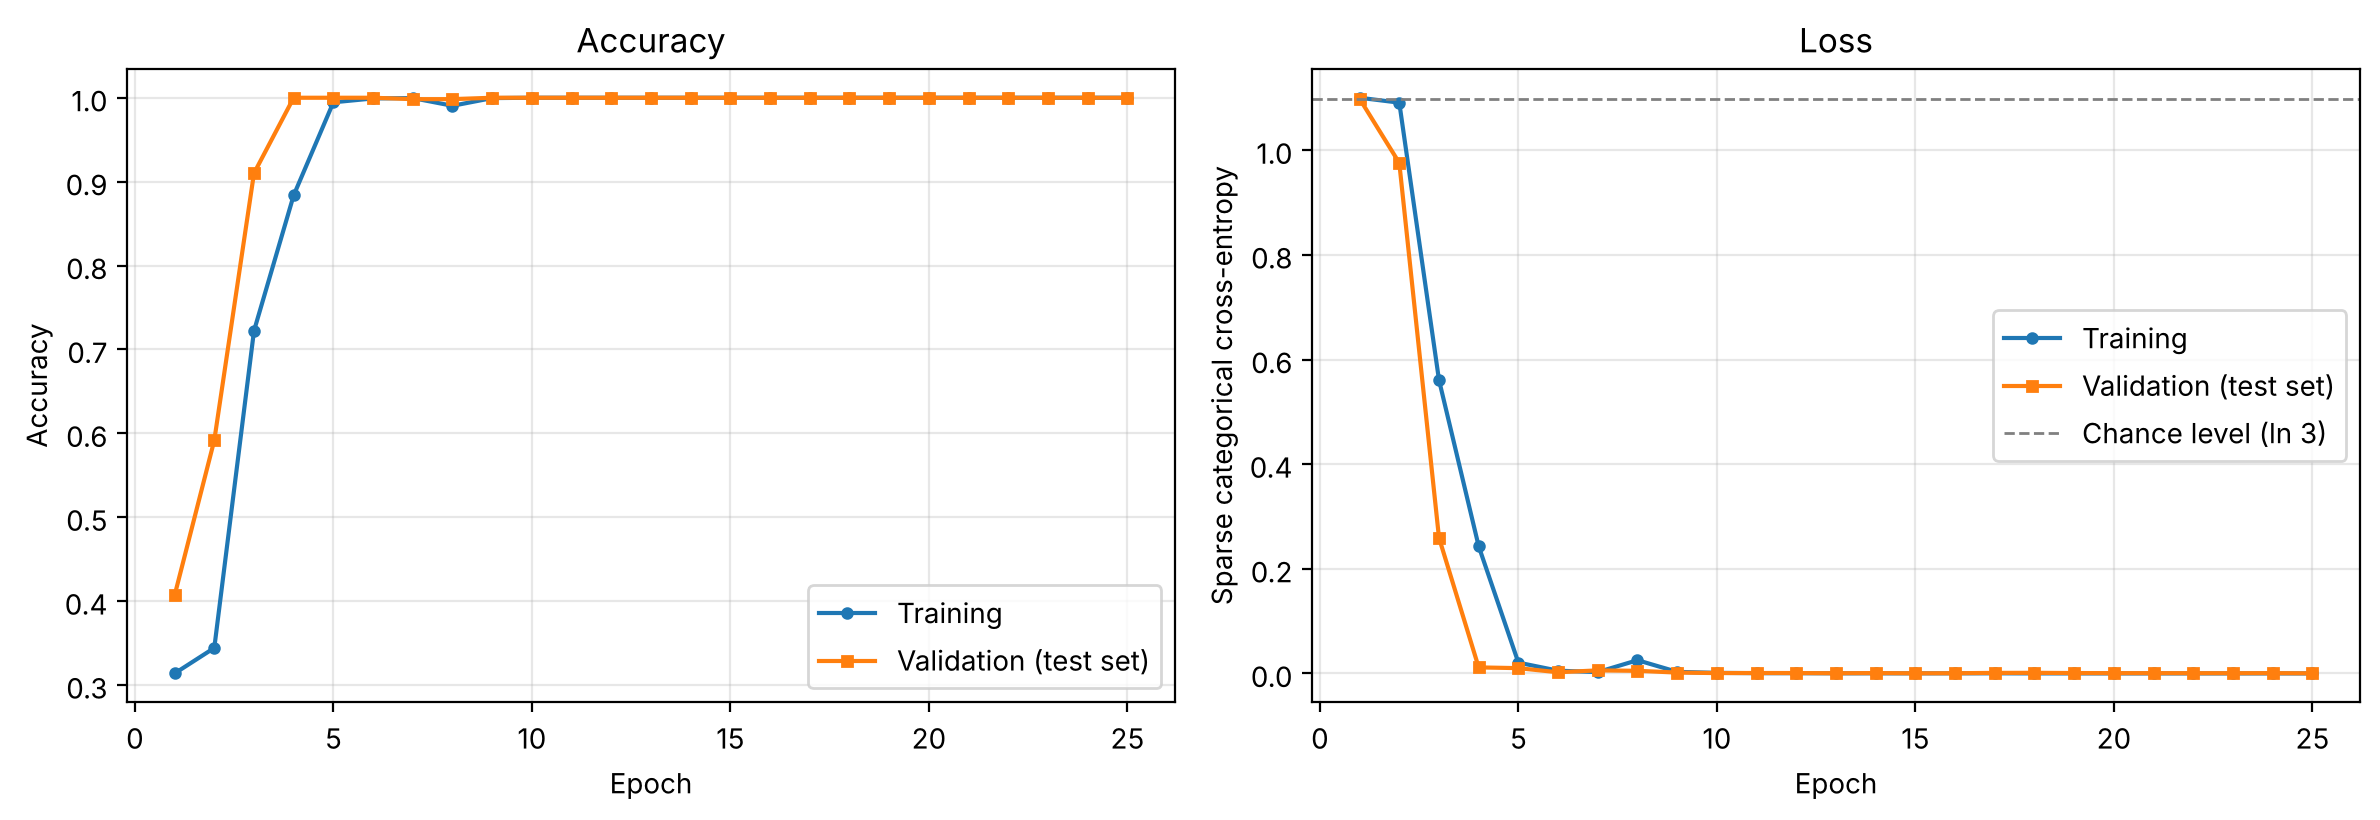

In [11]:
h = history.history
epochs = range(1, len(h["loss"]) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))

ax1.plot(epochs, h["accuracy"], "o-", ms=3.5, label="Training")
ax1.plot(epochs, h["val_accuracy"], "s-", ms=3.5, label="Validation (test set)")
ax1.set_title("Accuracy")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Accuracy")
ax1.grid(alpha=0.3)
ax1.legend()

ax2.plot(epochs, h["loss"], "o-", ms=3.5, label="Training")
ax2.plot(epochs, h["val_loss"], "s-", ms=3.5, label="Validation (test set)")
ax2.axhline(np.log(3), color="gray", ls="--", lw=1, label="Chance level (ln 3)")
ax2.set_title("Loss")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Sparse categorical cross-entropy")
ax2.grid(alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()

In [12]:
y_prob = model.predict(x_test, batch_size=64, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

cm = confusion_matrix(y_test, y_pred)
print("Confusion matrix (rows = true, columns = predicted):")
print(cm)
print()
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4))

Confusion matrix (rows = true, columns = predicted):
[[207   0   0]
 [  0 195   0]
 [  0   0 198]]

              precision    recall  f1-score   support

      Circle     1.0000    1.0000    1.0000       207
   Rectangle     1.0000    1.0000    1.0000       195
    Triangle     1.0000    1.0000    1.0000       198

    accuracy                         1.0000       600
   macro avg     1.0000    1.0000    1.0000       600
weighted avg     1.0000    1.0000    1.0000       600



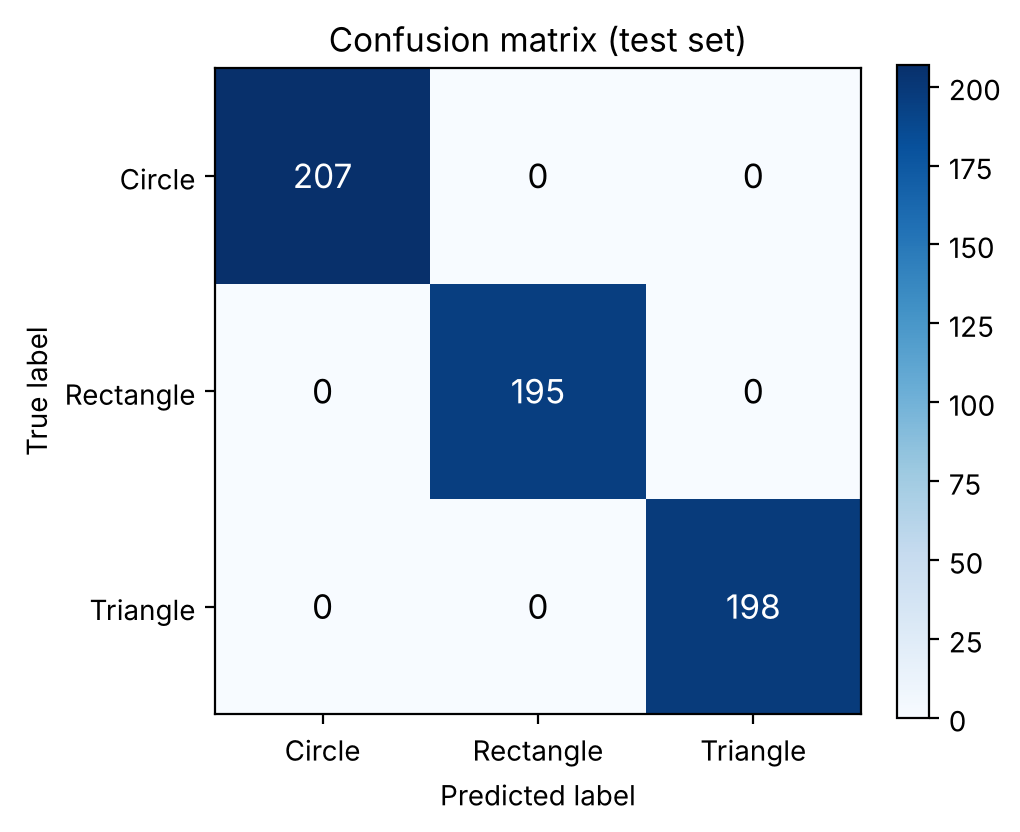

In [13]:
fig, ax = plt.subplots(figsize=(5, 4.3))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(3), CLASS_NAMES)
ax.set_yticks(range(3), CLASS_NAMES)
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_title("Confusion matrix (test set)")
for i in range(3):
    for j in range(3):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=12)
fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

Misclassified test images: 0 of 600


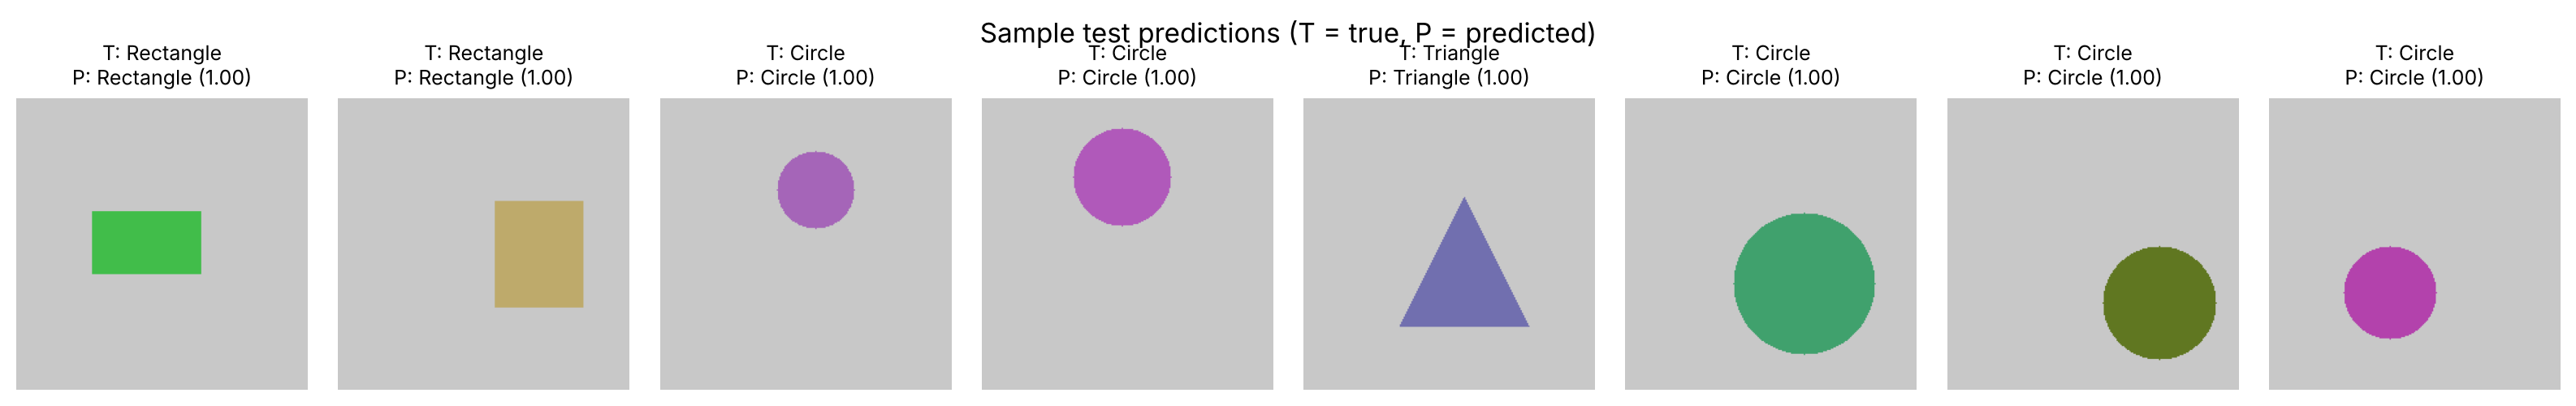

In [14]:
wrong = np.where(y_pred != y_test)[0]
print("Misclassified test images:", len(wrong), "of", len(y_test))

# show the mistakes if there are any, otherwise the first 8 test predictions
show = wrong[:8] if len(wrong) > 0 else np.arange(8)
title = "Misclassified test images" if len(wrong) > 0 else "Sample test predictions (T = true, P = predicted)"
fig, axes = plt.subplots(1, len(show), figsize=(2 * len(show), 2.5))
for ax, i in zip(np.atleast_1d(axes), show):
    ax.imshow(x_test[i])
    ax.set_title(f"T: {CLASS_NAMES[y_test[i]]}\nP: {CLASS_NAMES[y_pred[i]]} ({y_prob[i].max():.2f})", fontsize=9)
    ax.axis("off")
plt.suptitle(title)
plt.tight_layout()
plt.show()

## 7. Observations

**Final result:** test loss **0.0002**, test accuracy **100.00 %** (600 / 600), confusion matrix is purely diagonal.

**1. Stuck at chance for the first two epochs.** Loss stays at 1.1004 and 1.0910, which is ln 3 = 1.0986, and training
accuracy is about 33 %. The network is outputting roughly uniform probabilities. This is expected for an 8-layer
network with random weights, no batch normalisation and a small learning rate: it takes a while before the gradient
signal through five conv layers is strong enough to move the output away from uniform.

**2. Then the loss falls too fast.** Between epoch 2 and epoch 4 the training loss drops from 1.09 to 0.24 and test
accuracy goes from 59 % to 100 %. That is suspiciously quick, and I think the reason is the dataset, not the model:

- each image is one solid shape on a flat grey background, with no noise, texture, rotation or occlusion;
- triangles always have exactly the same size and orientation, only their position changes;
- the three classes differ in corners and straight edges, which the 11 x 11 filters in Conv1 pick up almost immediately;
- the test set comes from the same generator, so 100 % says the task is easy, not that the model generalises well.

**3. Validation accuracy is higher than training accuracy in epochs 1 to 4** (e.g. 0.91 vs 0.72 at epoch 3).
Training accuracy is averaged over the whole epoch while the weights are still improving, and it is measured with
dropout switched on. Validation is measured once at the end of the epoch with dropout off.

**4. Spike at epoch 8.** Training loss jumps from 0.0026 to 0.0253 and accuracy drops to 0.9904, then recovers in
epoch 9. My guess is one large Adam step: once gradients are tiny, Adam's per-parameter scaling can make a few
updates unusually big. Validation accuracy only dipped to 0.9983, so it did not do lasting damage.

**5. After epoch 10 nothing useful is learned.** Training loss keeps shrinking to about 2e-5 while validation loss
stays between 2e-4 and 1e-3, roughly ten times higher. The model is becoming over-confident on the training set
(the 58 M parameters, 37.7 M of them in FC1, can easily memorise 2400 images), but accuracy cannot improve past 100 %.
Early stopping around epoch 6 would give the same result in a quarter of the time.

**6. LRN is active.** The check in Section 3 shows each value divided by 1.68 when its neighbours are small
(= 2<sup>0.75</sup>) and by 2.34 inside the burst of large activations, so it is suppressing strongly active neighbouring channels as intended.